# Position held: dated works and positions of four individuals

In [1]:
import json
import re
import sys
import tempfile

import duckdb
import matplotlib.pyplot as plt
import polars as pl

sys.path.insert(0, '../../../notebooks/notebooks_analysis')
from matplotlib.lines import Line2D
from matplotlib.patches import Patch
from style import *

DB_PATH = '../../../data/cultura/cultura_enriched_v3.2.duckdb'  # read only: birth years
POSITIONS_PATH = '../../../data/raw_data_from_wikidata/wikidata_extraction_scripts_v2/life_locations/position_held_P39_statements.json'  # raw P39 statements
TARGETS_PATH = '../../../data/raw_data_from_wikidata/wikidata_extraction_scripts_v2/life_locations/targets.json'  # raw labels of the positions
FIRST_CENTURY, LAST_CENTURY = -500, 1900
CENTURY = 100  # years
PEOPLE = {'Q140412': 'John Donne', 'Q154959': 'Hugo Grotius', 'Q265398': 'Clara Peeters', 'Q296367': 'Hong Taiji'}  # contemporaries, all alive 1592–1631: Europe and China, culture, science and leadership, one woman
WORK_COLOR, POSITION_COLOR = '#D55E00', '#0072B2'  # Okabe-Ito vermillion and blue: distinct hues, colorblind-safe, readable as text
LIFELINE_COLOR = '#b0b6bd'
MILESTONE_COLORS = {'first work': WORK_COLOR, 'last work': WORK_COLOR, 'first position': POSITION_COLOR, 'last position': POSITION_COLOR}
MILESTONE_SIDES = {'first work': 1, 'last work': 1, 'first position': -1, 'last position': -1}  # works above the timeline, positions below; of two labels on a side, the first ends at its event and the second starts at its event

pl.Config.set_tbl_rows(40)
apply_style()

## Data
Wikidata position held (P39) statements with a start (P580) and an end (P582).

In [2]:
def year(value):
    sign, digits = re.match(r'([+-]?)(\d+)-', value['time']).groups()
    return -int(digits) if sign == '-' else int(digits)


raw = json.load(open(POSITIONS_PATH))
positions = pl.DataFrame(
    [
        {'qid': qid, 'position_qid': statement['target'],
         'start_year': year(statement['start']) if statement['start'] else None, 'start_precision': statement['start']['precision'] if statement['start'] else None,
         'end_year': year(statement['end']) if statement['end'] else None, 'end_precision': statement['end']['precision'] if statement['end'] else None,
         'point_in_time': statement['point_in_time'] is not None}
        for qid, statements in raw.items() for statement in statements if statement['rank'] != 'deprecated'
    ],
    schema={'qid': pl.String, 'position_qid': pl.String, 'start_year': pl.Int64, 'start_precision': pl.Int64, 'end_year': pl.Int64, 'end_precision': pl.Int64, 'point_in_time': pl.Boolean},
)
del raw
dated = positions.filter(pl.col('start_year').is_not_null() & pl.col('end_year').is_not_null())
print(f"{positions['qid'].n_unique():,} individuals with a position held, {dated['qid'].n_unique():,} with at least one position with a start and an end")
dated.sample(5, seed=42)

979,289 individuals with a position held, 454,417 with at least one position with a start and an end


qid,position_qid,start_year,start_precision,end_year,end_precision,point_in_time
str,str,i64,i64,i64,i64,bool
"""Q65593540""","""Q65482993""",2014,11,2020,11,false
"""Q21001584""","""Q18171345""",2009,11,2011,11,false
"""Q98247472""","""Q65477748""",2020,11,2026,11,false
"""Q6214979""","""Q81531912""",1873,9,1875,9,false
"""Q65585278""","""Q65192029""",2014,11,2020,11,false


### Example individuals
Four contemporaries alive from 1592 to 1631.

In [7]:
position_spans = dated.group_by('qid').agg(
    pl.col('start_year').min().alias('first_position'),
    pl.col('position_qid').sort_by('start_year').first().alias('first_position_qid'),
    pl.col('end_year').max().alias('last_position'),
    pl.col('position_qid').sort_by('end_year').last().alias('last_position_qid'),
)
con = duckdb.connect(DB_PATH, read_only=True)
con.register('position_spans', position_spans.to_arrow())
people = con.sql('''
    SELECT individual_enriched.entity.qid AS qid,
           individual_enriched.entity.label_en AS name,
           individual_enriched.birth_date.year AS birth_year,
           individual_enriched.death_date.year AS death_year,
           position_spans.first_position,
           position_spans.first_position_qid,
           position_spans.last_position,
           position_spans.last_position_qid
    FROM   individual_enriched
    LEFT JOIN position_spans ON position_spans.qid = individual_enriched.entity.qid
    WHERE  list_contains($qids, individual_enriched.entity.qid)
''', params={'qids': list(PEOPLE)}).pl()

works = con.sql('''
    WITH dated AS (
        SELECT individual_work.qid,
               coalesce(work.entity.label_en, work.entity.label_non_en) AS work_name,
               CASE WHEN list_contains(['day', 'month', 'year', 'decade'], work.inception.precision) THEN work.inception ELSE work.publication_date END AS date
        FROM   individual_work
        JOIN   work ON work.entity.qid = individual_work.work_qid
        WHERE  list_contains($qids, individual_work.qid)
    )
    SELECT qid, work_name, date.year + CASE WHEN date.precision = 'decade' THEN 5 ELSE 0 END AS year
    FROM   dated
    WHERE  list_contains(['day', 'month', 'year', 'decade'], date.precision) AND work_name IS NOT NULL
''', params={'qids': list(PEOPLE)}).pl()
con.close()

work_spans = (
    works.join(people.select('qid', 'birth_year', 'death_year'), on='qid')
    .filter(pl.col('year').is_between('birth_year', 'death_year'))  # a work date must fall inside the lifetime (cleaning rule 2 of 03_b_active_life)
    .group_by('qid').agg(pl.col('year').min().alias('first_work'), pl.col('year').max().alias('last_work'))
)
people = people.join(work_spans, on='qid', how='left')

first_names = works.join(people.select('qid', 'first_work'), on='qid').filter(pl.col('year') == pl.col('first_work')).group_by('qid').agg(pl.col('work_name').min().alias('first_work_name'))
last_names = works.join(people.select('qid', 'last_work'), on='qid').filter(pl.col('year') == pl.col('last_work')).group_by('qid').agg(pl.col('work_name').min().alias('last_work_name'))

targets = json.load(open(TARGETS_PATH))
position_label = {qid: (targets.get(qid) or {}).get('label_en') or qid for qid in [*people['first_position_qid'].drop_nulls(), *people['last_position_qid'].drop_nulls()]}
del targets
people = (
    people.join(first_names, on='qid', how='left').join(last_names, on='qid', how='left')
    .with_columns(
        pl.col('first_position_qid').replace_strict(position_label, default=None).alias('first_position_name'),
        pl.col('last_position_qid').replace_strict(position_label, default=None).alias('last_position_name'),
    )
    .sort('birth_year')
)
assert people.height == len(PEOPLE)
people.select('name', 'birth_year', 'first_work', 'first_work_name', 'last_work', 'last_work_name', 'first_position', 'first_position_name', 'last_position', 'last_position_name', 'death_year')

name,birth_year,first_work,first_work_name,last_work,last_work_name,first_position,first_position_name,last_position,last_position_name,death_year
str,i64,i64,str,i64,str,i64,str,i64,str,i64
"""John Donne""",1572,1609,"""Death Be Not Proud""",1624,"""Devotions upon Emergent Occasi…",1621,"""Dean of St Paul's""",1631,"""Dean of St Paul's""",1631
"""Hugo Grotius""",1583,1608,"""Christus patiens""",1625,"""De jure belli ac pacis""",1613,"""Pensionary""",1618,"""Pensionary""",1645
"""Clara Peeters""",1587,1600,"""Flowers in a glass beaker, wit…",1640,"""Basket of red and green grapes…",null,null,null,null,1657
"""Hong Taiji""",1592,null,null,null,null,1626,"""khan""",1643,"""Emperor of China""",1643


## Figures
### Figure 1: Dates recorded in Wikidata for four individuals born in the 16th century

/var/folders/lx/9b13r6ln63jb54_3xlf9b_380000gn/T/ipykernel_88853/3856337526.py:47: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


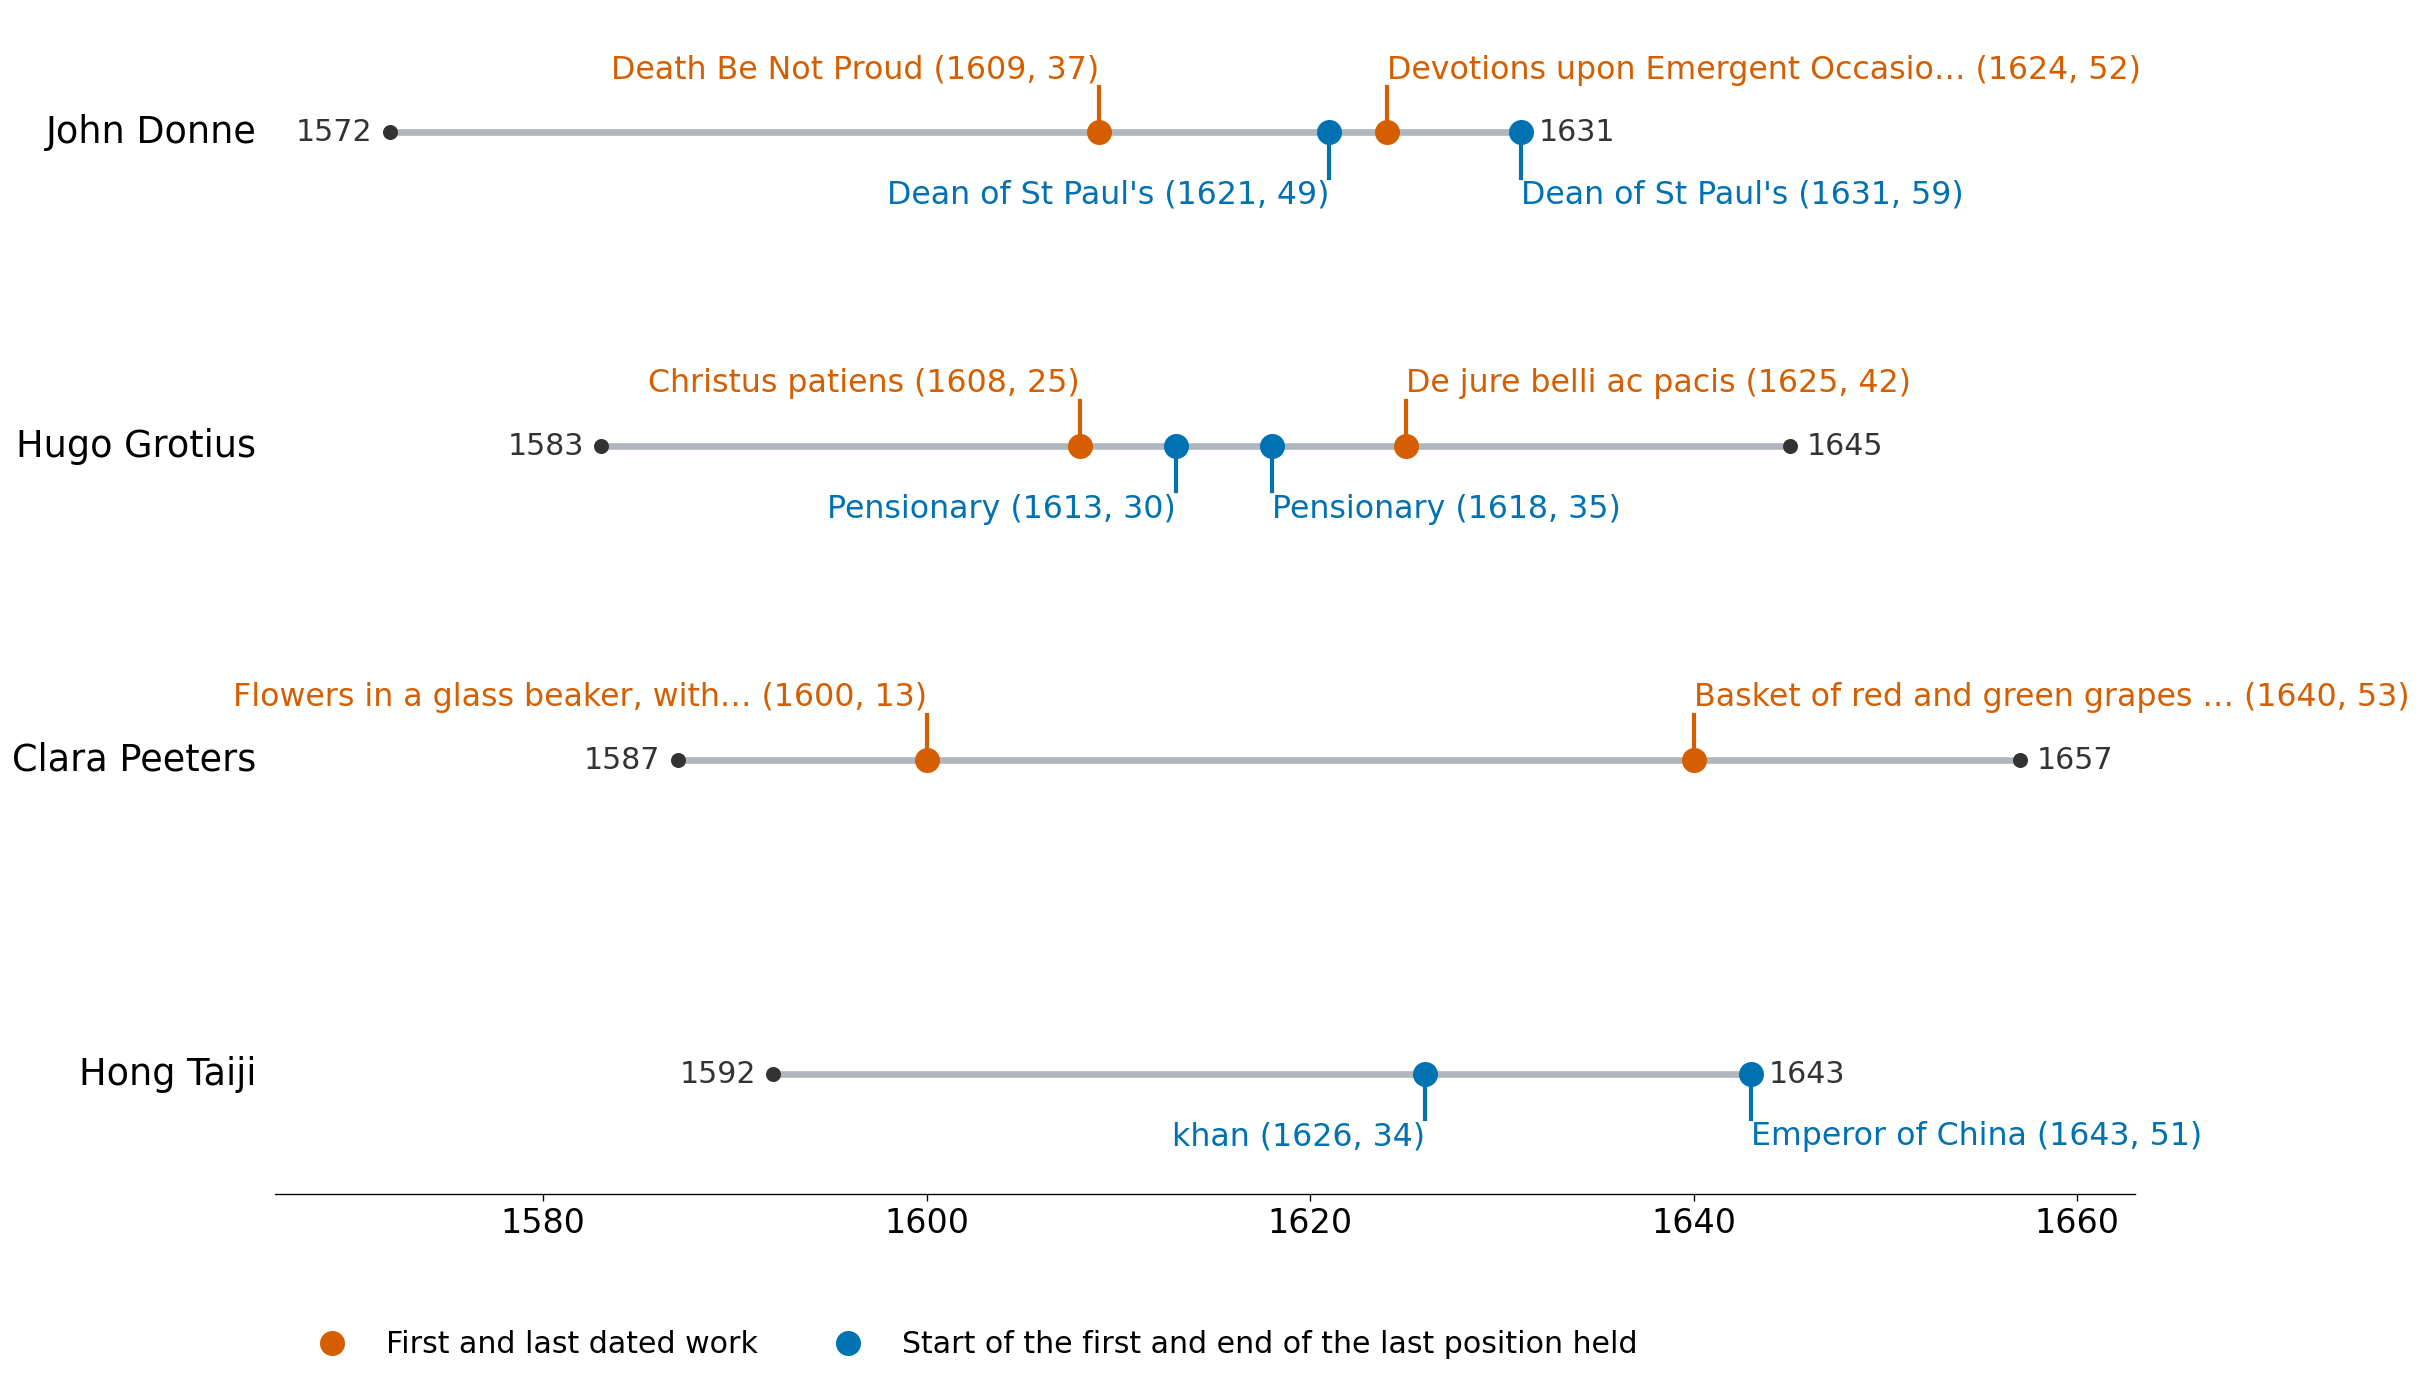

In [10]:
def shorten(text, size=32):
    return text if len(text) <= size else text[:size - 1] + '…'


def milestones(person):
    found = []
    for event, year, name in [('first work', person['first_work'], person['first_work_name']), ('last work', person['last_work'], person['last_work_name']),
                              ('first position', person['first_position'], person['first_position_name']), ('last position', person['last_position'], person['last_position_name'])]:
        if year is not None and name is not None:
            found.append((event, year, name))
    return found


def plot_milestones(frame):
    fig, axes = plt.subplots(frame.height, 1, figsize=(20, 3.2 * frame.height), sharex=True, gridspec_kw={'hspace': 0.3})
    for ax, person in zip(axes, frame.iter_rows(named=True)):
        birth, death = person['birth_year'], person['death_year']
        ax.plot([birth, death], [0, 0], color=LIFELINE_COLOR, linewidth=4, zorder=1)
        for year, ha, shift in [(birth, 'right', -1.5), (death, 'left', 1.5)]:
            ax.plot(year, 0, 'o', color=TEXT, markersize=8, zorder=2)
            ax.text(year + shift * 0.6, 0, year, ha=ha, va='center', fontsize=18, color=TEXT)
        previous = {}
        for event, year, name in sorted(milestones(person), key=lambda milestone: milestone[1]):
            side = MILESTONE_SIDES[event]
            close = side in previous
            color = MILESTONE_COLORS[event]
            ax.plot([year, year], [0, side * 1.2], color=color, linewidth=2.5, zorder=1)
            ax.plot(year, 0, 'o', color=color, markersize=14, zorder=3)
            label = ax.text(year, side * 1.25, f'{shorten(name)} ({year}, {year - birth})', ha='left' if close else 'center',
                            va='top' if side < 0 else 'bottom', fontsize=19, color=color)
            if close:
                previous[side].set_horizontalalignment('right')
            previous[side] = label
        ax.text(-0.01, 0, person['name'], transform=ax.get_yaxis_transform(), ha='right', va='center', fontsize=22, color='black')
        ax.set_ylim(-3.2, 3.2)
        ax.set_yticks([])
        for spine in ('left', 'top', 'right', 'bottom'):
            ax.spines[spine].set_visible(False)
        ax.tick_params(axis='x', length=0)
    axes[-1].spines['bottom'].set_visible(True)
    axes[-1].tick_params(axis='x', length=4, labelsize=20)
    axes[-1].set_xlim(frame['birth_year'].min() - 6, frame['death_year'].max() + 6)
    axes[-1].legend(handles=[
        Line2D([], [], marker='o', linestyle='', markersize=14, color=WORK_COLOR, label='First and last dated work'),
        Line2D([], [], marker='o', linestyle='', markersize=14, color=POSITION_COLOR, label='Start of the first and end of the last position held'),
    ], loc='upper left', bbox_to_anchor=(0, -0.45), ncol=2, fontsize=18)
    plt.tight_layout()
    plt.show()


plot_milestones(people)